# Обучаемая PReLU

Сначала обучим отдельный коэффициент PReLU, затем посмотрим, как меняются наклоны активации при решении XOR.


## Ход работы

Начинаем с отдельного обучаемого коэффициента: задаём начальный наклон 0.25 и отслеживаем его приближение к 0.5. Этот небольшой опыт позволяет увидеть изменение параметра активации отдельно от весов нейронной сети.

Затем подготавливаем XOR и обучаем сети с ReLU, LeakyReLU и PReLU. Для PReLU сохраняем значения наклонов по мере обучения. Сравниваем кривые MSE и число эпох до порога, а на графиках коэффициентов смотрим, одинаково ли меняются параметры разных нейронов и принимают ли они отрицательные значения.


### Один обучаемый наклон в простом опыте

Задаём параметр, который должен приблизиться к 0.5, и оптимизатор. Этот опыт изолирует обучаемый коэффициент от остальных весов MLP.

In [1]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)

import torch
from torch import nn

# Входные данные
X = torch.tensor([[-2.0], [-1.0], [1.0], [2.0]])

# Желаемые результаты
y = torch.tensor([[-1.0], [-0.5], [1.0], [2.0]])

# PReLU с начальным коэффициентом 0.25
model = nn.PReLU(num_parameters=1, init=0.25)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)


### Наблюдаем движение коэффициента a

Обучаем параметр и следим за loss. Если коэффициент начался с 0.25, то изменение к 0.5 показывает работу `backward()` и `step()` с параметрами самой активации.

In [2]:

loss_fn = nn.MSELoss()

print("Начальный a:", model.weight.item())

for epoch in range(100):
    optimizer.zero_grad()

    predictions = model(X)
    loss = loss_fn(predictions, y)

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Loss: {loss.item():.6f} | "
            f"a: {model.weight.item():.6f}"
        )

print("\nИтоговый a:", model.weight.item())

with torch.no_grad():
    print("Предсказания:")
    print(model(X))

import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt


Начальный a: 0.25
Epoch  10 | Loss: 0.007062 | a: 0.434231
Epoch  20 | Loss: 0.000489 | a: 0.482698
Epoch  30 | Loss: 0.000034 | a: 0.495448
Epoch  40 | Loss: 0.000002 | a: 0.498803
Epoch  50 | Loss: 0.000000 | a: 0.499685
Epoch  60 | Loss: 0.000000 | a: 0.499917
Epoch  70 | Loss: 0.000000 | a: 0.499978
Epoch  80 | Loss: 0.000000 | a: 0.499994
Epoch  90 | Loss: 0.000000 | a: 0.499998
Epoch 100 | Loss: 0.000000 | a: 0.500000

Итоговый a: 0.4999995827674866
Предсказания:
tensor([[-1.0000],
        [-0.5000],
        [ 1.0000],
        [ 2.0000]])


### Готовим XOR и список функций

Переходим к нелинейной задаче с четырьмя точками и задаём сравниваемые ReLU, LeakyReLU и PReLU. Изменяется тип скрытой активации, а не размерность входа или ответа.

In [3]:

X = torch.tensor([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y = torch.tensor([
    [0.],
    [1.],
    [1.],
    [0.]
])

activations = {
    "ReLU": lambda: nn.ReLU(),
    "LeakyReLU": lambda: nn.LeakyReLU(0.01),
    "PReLU": lambda: nn.PReLU(
        num_parameters=8,
        init=0.25
    )
}

target_mse = 0.001


### Обучение активаций и сохранение коэффициентов

Для каждой сети измеряем количество эпох до `MSE < 0.001`. У PReLU параметр `a` обучается вместе с весами соседних `Linear`; если каждому нейрону назначен свой `a`, коэффициенты могут разойтись.


=== ReLU ===
Эпоха сходимости: 75
Итоговая MSE: 5.551115123125783e-17
Предсказания: [-0.  1.  1.  0.]



=== LeakyReLU ===
Эпоха сходимости: 76
Итоговая MSE: 4.996003610813204e-16
Предсказания: [0. 1. 1. 0.]



=== PReLU ===
Эпоха сходимости: 60
Итоговая MSE: 1.1102230246251565e-16
Предсказания: [-0.  1.  1.  0.]
Начальный a: 0.25
Обученные коэффициенты a:
[ 0.25    0.4603  0.0988  0.7342 -0.8376 -0.5812  0.3136  1.1283]


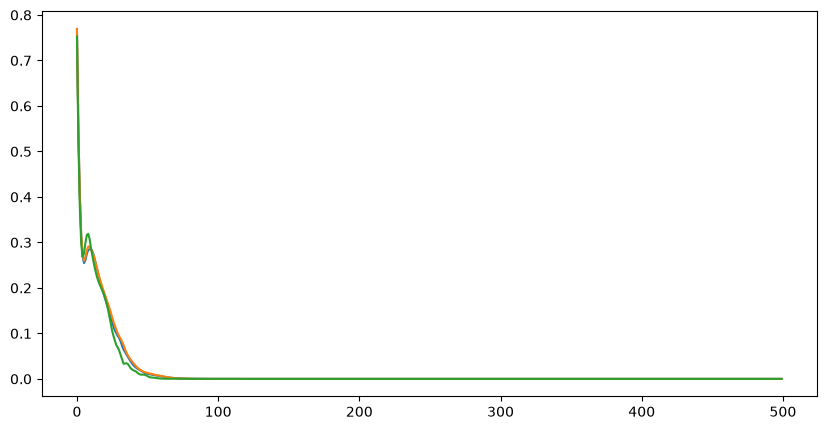

In [4]:
epochs = 500

plt.figure(figsize=(10, 5))

for name, create_activation in activations.items():

    torch.manual_seed(42)

    model = nn.Sequential(
        nn.Linear(2, 8),
        create_activation(),
        nn.Linear(8, 1)
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.03
    )

    loss_fn = nn.MSELoss()

    history = []
    a_history = []
    convergence_epoch = None

    for epoch in range(epochs):

        optimizer.zero_grad()

        predictions = model(X)
        loss = loss_fn(predictions, y)

        loss.backward()
        optimizer.step()

        with torch.no_grad():
            current_loss = loss_fn(model(X), y).item()

        history.append(current_loss)

        if name == "PReLU":
            a_history.append(
            model[1].weight.detach().numpy().copy()
            )

        if current_loss < target_mse and convergence_epoch is None:
            convergence_epoch = epoch + 1

    with torch.no_grad():
        final_predictions = model(X)

    print(f"\n=== {name} ===")
    print("Эпоха сходимости:", convergence_epoch)
    print("Итоговая MSE:", history[-1])
    print("Предсказания:",
          final_predictions.flatten().numpy().round(3))

    if name == "PReLU":
        print("Начальный a: 0.25")
        print("Обученные коэффициенты a:")
        print(model[1].weight.detach().numpy().round(4))

    plt.plot(history, label=name)


### Как читать график MSE

Подписи осей и легенда показывают, какую кривую мы рассматриваем. Различия в эпохах — наблюдение конкретного запуска, а не универсальное превосходство одной функции.

C:\Users\Dad\AppData\Local\Temp\ipykernel_28004\2959499093.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


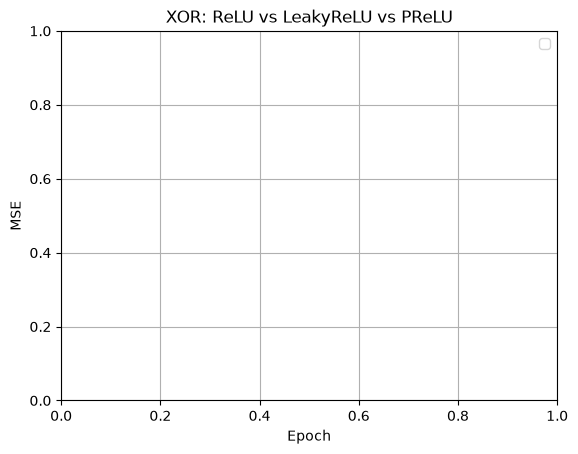

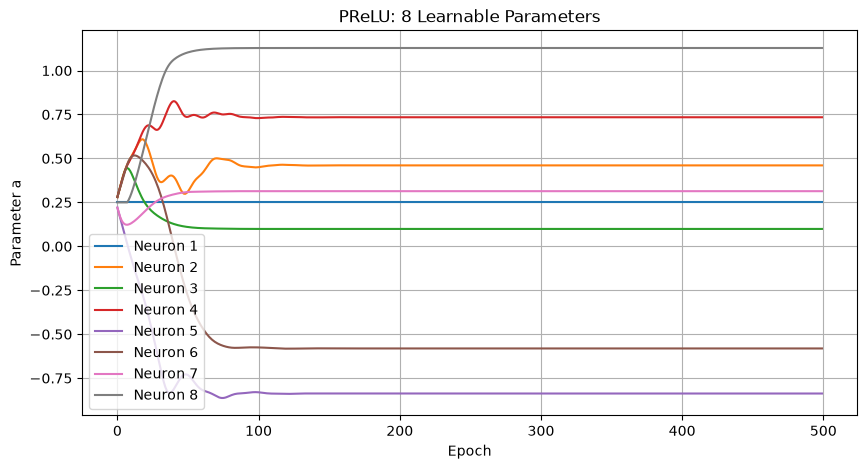

In [5]:

plt.title("XOR: ReLU vs LeakyReLU vs PReLU")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid()
plt.show()

# Отдельный график изменения коэффициента PReLU
a_history = np.array(a_history)

plt.figure(figsize=(10, 5))

for i in range(8):
    plt.plot(
        a_history[:, i],
        label=f"Neuron {i + 1}"
    )

plt.xlabel("Epoch")
plt.ylabel("Parameter a")
plt.title("PReLU: 8 Learnable Parameters")
plt.legend()
plt.grid()


### Показываем график

Сопоставляем кривые MSE с изменениями коэффициентов PReLU.

In [6]:
plt.show()


## Выводы

В отдельном опыте наклон приближается к 0.5. В XOR коэффициенты разных нейронов меняются по-разному и могут стать отрицательными: ограничения на знак в модели нет.


## Полный код


Начальный a: 0.25
Epoch  10 | Loss: 0.007062 | a: 0.434231
Epoch  20 | Loss: 0.000489 | a: 0.482698
Epoch  30 | Loss: 0.000034 | a: 0.495448
Epoch  40 | Loss: 0.000002 | a: 0.498803
Epoch  50 | Loss: 0.000000 | a: 0.499685
Epoch  60 | Loss: 0.000000 | a: 0.499917
Epoch  70 | Loss: 0.000000 | a: 0.499978
Epoch  80 | Loss: 0.000000 | a: 0.499994
Epoch  90 | Loss: 0.000000 | a: 0.499998
Epoch 100 | Loss: 0.000000 | a: 0.500000

Итоговый a: 0.4999995827674866
Предсказания:
tensor([[-1.0000],
        [-0.5000],
        [ 1.0000],
        [ 2.0000]])

=== ReLU ===
Эпоха сходимости: 75
Итоговая MSE: 5.551115123125783e-17
Предсказания: [-0.  1.  1.  0.]



=== LeakyReLU ===
Эпоха сходимости: 76
Итоговая MSE: 4.996003610813204e-16
Предсказания: [0. 1. 1. 0.]

=== PReLU ===
Эпоха сходимости: 60
Итоговая MSE: 1.1102230246251565e-16
Предсказания: [-0.  1.  1.  0.]
Начальный a: 0.25
Обученные коэффициенты a:
[ 0.25    0.4603  0.0988  0.7342 -0.8376 -0.5812  0.3136  1.1283]


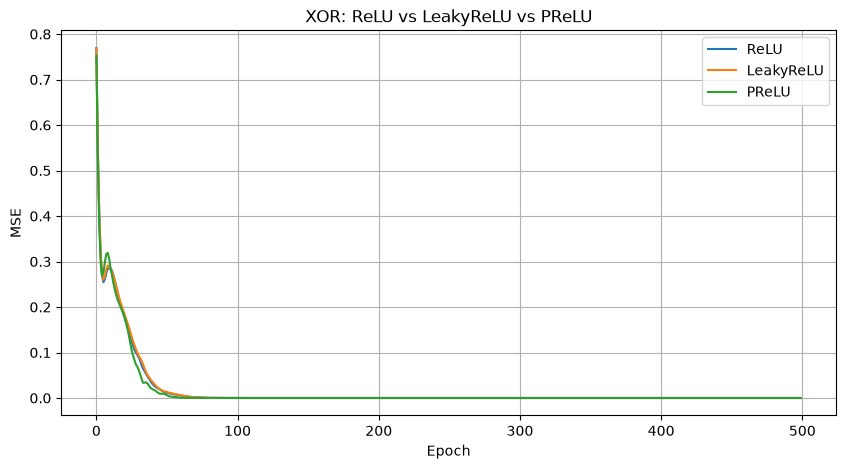

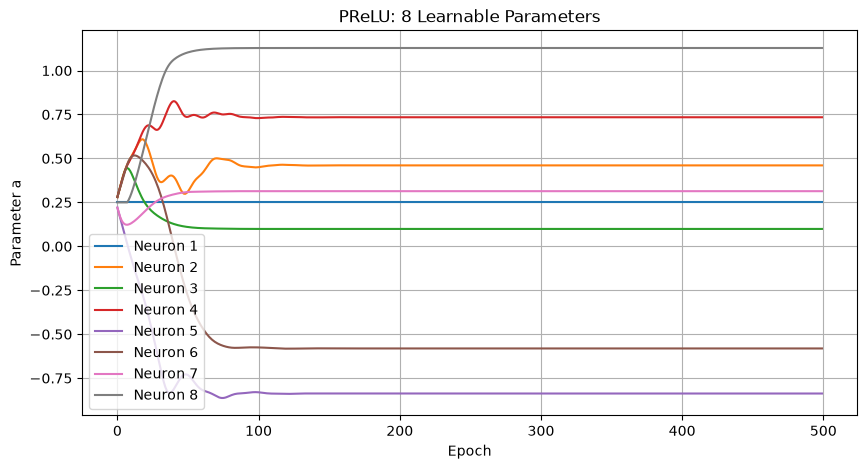

In [7]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)

import torch
from torch import nn

# Входные данные
X = torch.tensor([[-2.0], [-1.0], [1.0], [2.0]])

# Желаемые результаты
y = torch.tensor([[-1.0], [-0.5], [1.0], [2.0]])

# PReLU с начальным коэффициентом 0.25
model = nn.PReLU(num_parameters=1, init=0.25)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)

loss_fn = nn.MSELoss()

print("Начальный a:", model.weight.item())

for epoch in range(100):
    optimizer.zero_grad()

    predictions = model(X)
    loss = loss_fn(predictions, y)

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Loss: {loss.item():.6f} | "
            f"a: {model.weight.item():.6f}"
        )

print("\nИтоговый a:", model.weight.item())

with torch.no_grad():
    print("Предсказания:")
    print(model(X))

import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

X = torch.tensor([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y = torch.tensor([
    [0.],
    [1.],
    [1.],
    [0.]
])

activations = {
    "ReLU": lambda: nn.ReLU(),
    "LeakyReLU": lambda: nn.LeakyReLU(0.01),
    "PReLU": lambda: nn.PReLU(
        num_parameters=8,
        init=0.25
    )
}

target_mse = 0.001
epochs = 500

plt.figure(figsize=(10, 5))

for name, create_activation in activations.items():

    torch.manual_seed(42)

    model = nn.Sequential(
        nn.Linear(2, 8),
        create_activation(),
        nn.Linear(8, 1)
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.03
    )

    loss_fn = nn.MSELoss()

    history = []
    a_history = []
    convergence_epoch = None

    for epoch in range(epochs):

        optimizer.zero_grad()

        predictions = model(X)
        loss = loss_fn(predictions, y)

        loss.backward()
        optimizer.step()

        with torch.no_grad():
            current_loss = loss_fn(model(X), y).item()

        history.append(current_loss)

        if name == "PReLU":
            a_history.append(
            model[1].weight.detach().numpy().copy()
            )

        if current_loss < target_mse and convergence_epoch is None:
            convergence_epoch = epoch + 1

    with torch.no_grad():
        final_predictions = model(X)

    print(f"\n=== {name} ===")
    print("Эпоха сходимости:", convergence_epoch)
    print("Итоговая MSE:", history[-1])
    print("Предсказания:",
          final_predictions.flatten().numpy().round(3))

    if name == "PReLU":
        print("Начальный a: 0.25")
        print("Обученные коэффициенты a:")
        print(model[1].weight.detach().numpy().round(4))

    plt.plot(history, label=name)

plt.title("XOR: ReLU vs LeakyReLU vs PReLU")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid()
plt.show()

# Отдельный график изменения коэффициента PReLU
a_history = np.array(a_history)

plt.figure(figsize=(10, 5))

for i in range(8):
    plt.plot(
        a_history[:, i],
        label=f"Neuron {i + 1}"
    )

plt.xlabel("Epoch")
plt.ylabel("Parameter a")
plt.title("PReLU: 8 Learnable Parameters")
plt.legend()
plt.grid()
plt.show()
